In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv("uber.csv")
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [3]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


(200000, 9)

In [4]:
df.drop(columns=["Unnamed: 0", "key"], errors="ignore", inplace=True)
df.dropna(inplace=True)

In [5]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"], errors="coerce", utc=True)
df.dropna(subset=["pickup_datetime"], inplace=True)

In [6]:
df = df[
    (df["fare_amount"] > 0) &
    (df["fare_amount"] <= 200) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42)) &
    (df["passenger_count"].between(1, 6))
].copy()

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["weekday"] = df["pickup_datetime"].dt.dayofweek

In [7]:
lat1 = np.radians(df["pickup_latitude"])
lat2 = np.radians(df["dropoff_latitude"])

lon1 = np.radians(df["pickup_longitude"])
lon2 = np.radians(df["dropoff_longitude"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = (np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2)

df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))


In [10]:
df = df[df["distance"] > 0].copy()

print("Dataset after preprocessing:")
print(df.head())
print("Shape after preprocessing:", df.shape)

Dataset after preprocessing:
   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  hour  day  month  \
0         -73.999512         40.723217                1    19    7      5   
1         -73.994710         40.750325                1    20   17      7   
2         -73.962565         40.772647                1    21   24      8   
3         -73.965316         40.803349                3     8   26      6   
4         -73.973082         40.761247                5    17   28      8   

   weekday  distance  
0        3

In [11]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["fare_amount"] < lower) | (df["fare_amount"] > upper)]

print("Number of fare outliers:", len(outliers))


Number of fare outliers: 16513


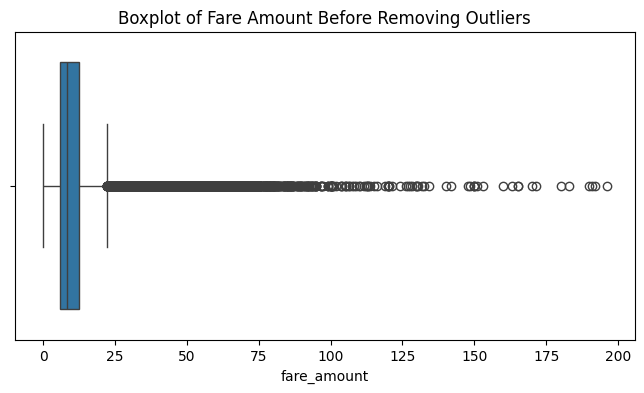

In [12]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Boxplot of Fare Amount Before Removing Outliers")
plt.show()

In [13]:
df = df[(df["fare_amount"] >= max(0, lower)) & (df["fare_amount"] <= upper)].copy()

print("Shape after removing outliers:", df.shape)


Shape after removing outliers: (176546, 12)


Correlation Matrix : 
                   pickup_longitude  pickup_latitude  dropoff_longitude  \
pickup_longitude           1.000000         0.392109           0.580662   
pickup_latitude            0.392109         1.000000           0.144896   
dropoff_longitude          0.580662         0.144896           1.000000   
dropoff_latitude           0.165715         0.562443           0.367591   
passenger_count           -0.013884        -0.009671          -0.010609   
hour                      -0.000916         0.034214          -0.031075   
day                       -0.001203        -0.000149          -0.004618   
month                      0.000701        -0.000183          -0.000296   
weekday                   -0.016789        -0.046278          -0.007029   
distance                   0.140293         0.006094           0.189791   
fare_amount                0.006241        -0.083255           0.092935   

                   dropoff_latitude  passenger_count      hour       day  \
p

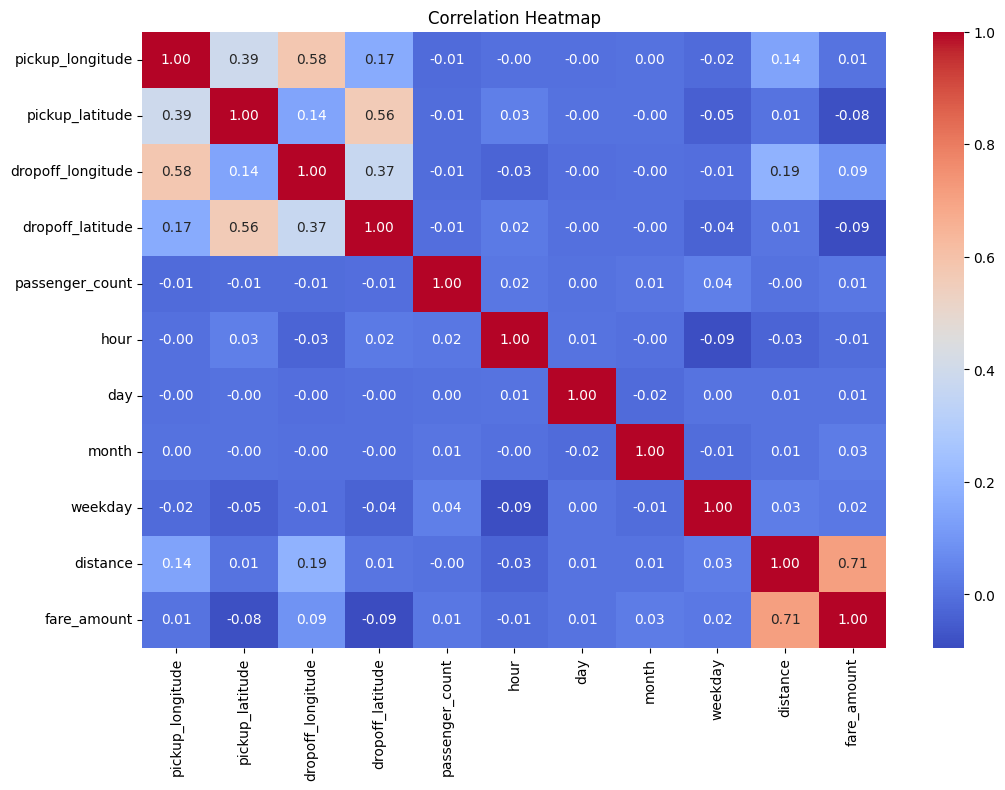

In [14]:
features = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "hour",
    "day",
    "month",
    "weekday",
    "distance",
    "fare_amount"
]
correlation = df[features].corr()

print("Correlation Matrix : ")
print(correlation)

plt.figure(figsize=(12, 8))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [15]:
X = df.drop(columns=["fare_amount", "pickup_datetime"])
y = df["fare_amount"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (141236, 10)
Testing data: (35310, 10)


In [16]:
lr_model = make_pipeline(StandardScaler(), LinearRegression())
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

In [17]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [18]:
def evaluate_model(name, actual, predicted):
    r2 = r2_score(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)
    print("\n", name)
    print("R2 Score:", round(r2, 4))
    print("RMSE:", round(rmse, 4))
    print("MAE:", round(mae, 4))
    return [name, r2, rmse, mae]


lr_results = evaluate_model("Linear Regression", y_test, lr_pred)
rf_results = evaluate_model("Random Forest Regression", y_test, rf_pred)



 Linear Regression
R2 Score: 0.5493
RMSE: 2.7847
MAE: 1.9031

 Random Forest Regression
R2 Score: 0.7504
RMSE: 2.0726
MAE: 1.4612


In [19]:
results = pd.DataFrame([lr_results, rf_results], columns=["Model", "R2 Score", "RMSE", "MAE"])

print("\nModel Comparison:")
print(results.to_string(index=False))


Model Comparison:
                   Model  R2 Score     RMSE      MAE
       Linear Regression  0.549349 2.784700 1.903100
Random Forest Regression  0.750365 2.072577 1.461188


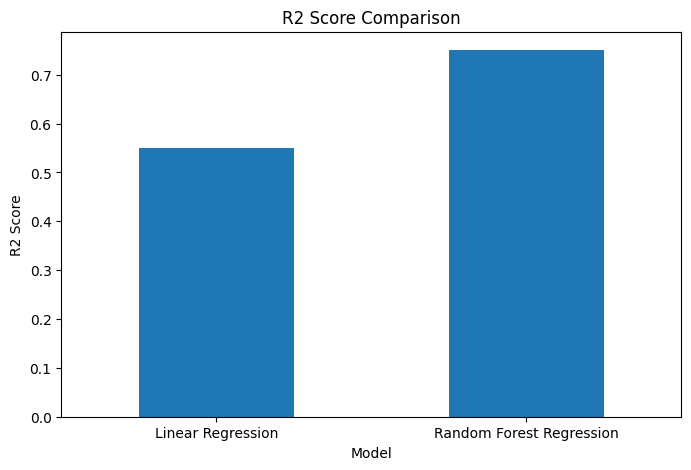

In [20]:
results.set_index("Model")[["R2 Score"]].plot( kind="bar", figsize=(8, 5), legend=False)

plt.title("R2 Score Comparison")
plt.ylabel("R2 Score")
plt.xticks(rotation=0)
plt.show()

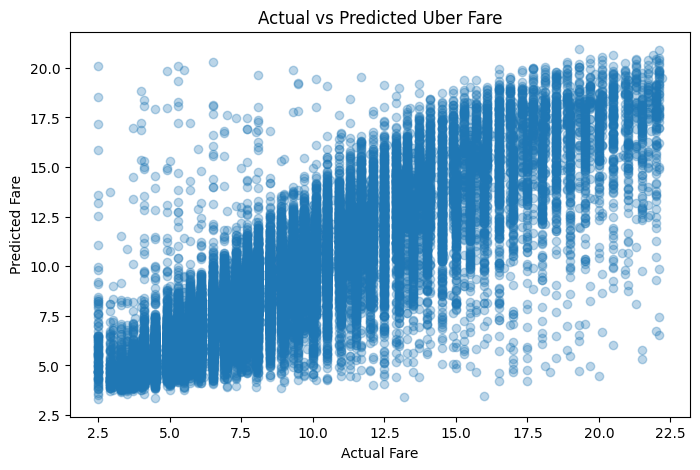

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, rf_pred, alpha=0.3)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Uber Fare")
plt.show()

In [22]:
sample = X_test.iloc[[0]]
prediction = rf_model.predict(sample)

print("Sample Ride Prediction:")
print("Predicted Uber Fare:", round(prediction[0], 2))
print("Actual Uber Fare:", round(y_test.iloc[0], 2))

Sample Ride Prediction:
Predicted Uber Fare: 7.76
Actual Uber Fare: 11.3
